In [ ]:
# Import Required Librares --

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Data Read --

df = pd.read_csv("/content/housing_data.csv")

df.head(10)

,House Size (sqft),Number of Bedrooms,Number of Bathrooms,House Age,Distance to City Center (miles),Number of Floors,Price
0,1748.357077,1,2,14.0,17.206366,1,255304.2945
1,1430.867849,5,3,91.0,2.820689,2,251530.7556
2,1823.844269,1,1,NaN,15.815819,3,173281.6186
3,2261.514928,3,1,65.0,10.051165,1,334259.6474
4,1382.923313,2,1,31.0,5.092457,1,207595.3383
5,1382.931522,4,1,86.0,12.310517,2,229875.2008
6,2289.606408,3,2,62.0,10.995298,3,346585.1920
7,1883.717365,1,1,85.0,6.998916,3,323844.9293
8,1265.262807,4,3,50.0,10.349010,1,242027.2718
9,1771.280022,1,3,24.0,8.073432,1,264546.9314


In [ ]:
# find information about the data  --
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   House Size (sqft)                100 non-null    float64
 1   Number of Bedrooms               100 non-null    int64  
 2   Number of Bathrooms              100 non-null    int64  
 3   House Age                        96 non-null     float64
 4   Distance to City Center (miles)  100 non-null    float64
 5   Number of Floors                 100 non-null    int64  
 6   Price                            100 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 5.6 KB


In [ ]:
# Check Missing Value --

df.isnull().sum()

,0
House Size (sqft),0
Number of Bedrooms,0
Number of Bathrooms,0
House Age,4
Distance to City Center (miles),0
Number of Floors,0
Price,0


In [ ]:
# Handle missing value --

df['House Age'].fillna(df['House Age'].median(),inplace =True)

/tmp/ipykernel_2583/2945954132.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['House Age'].fillna(df['House Age'].median(),inplace =True)


In [ ]:
# check again Missing Value --

df.isnull().sum()

,0
House Size (sqft),0
Number of Bedrooms,0
Number of Bathrooms,0
House Age,0
Distance to City Center (miles),0
Number of Floors,0
Price,0


In [ ]:
# EDA -- >



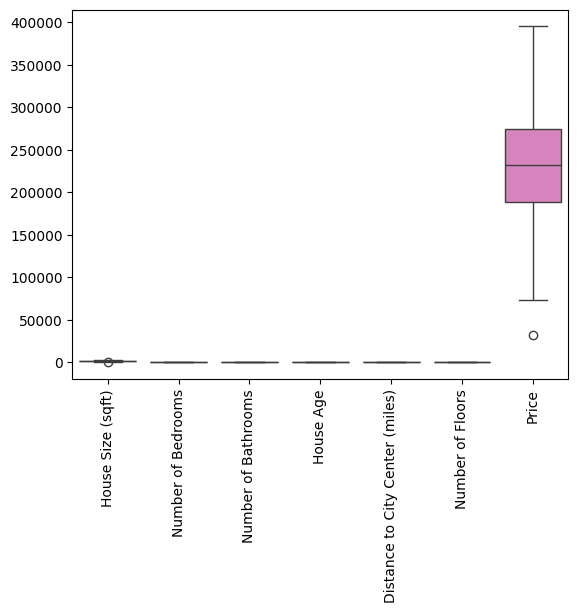

In [ ]:
# Find Outliers -- >>

sns.boxplot(df)
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Handle Outliers -->>

Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

Lowerrange = Q1 - IQR*1.5
Upperrange = Q3 + IQR*1.5

df_clean = df[~((df<Lowerrange)|(df>Upperrange)).any(axis=1)]

df_clean.shape

(99, 7)

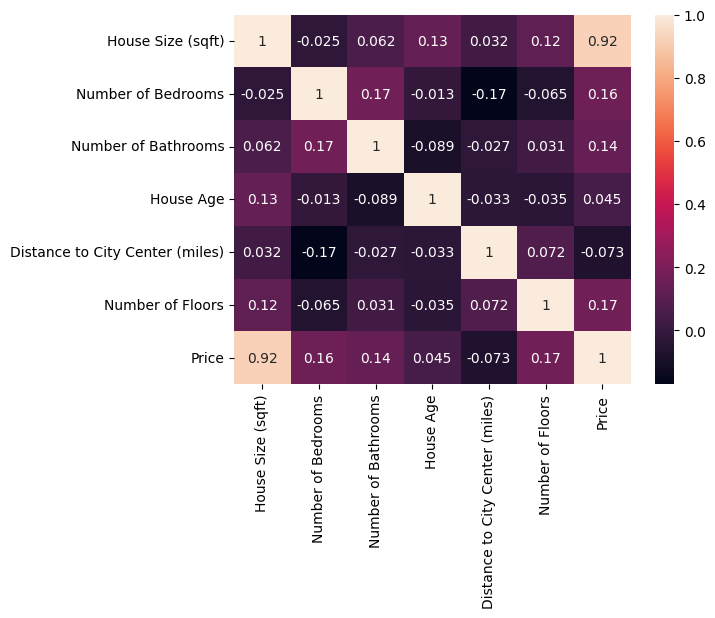

In [ ]:
# Create heatmap -->>

df_corr = df.corr(numeric_only=True)
sns.heatmap(df_corr,annot=True,fmt=".2g")
plt.show()


In [ ]:
df_clean.columns

Index(['House Size (sqft)', 'Number of Bedrooms', 'Number of Bathrooms',
       'House Age', 'Distance to City Center (miles)', 'Number of Floors',
       'Price'],
      dtype='object')

In [ ]:
# Feature Selection --

x = df_clean[['House Size (sqft)', 'Number of Bedrooms',
             'Number of Bathrooms', 'Number of Floors']]
y = df_clean['Price']


In [ ]:
# Data Splitting -->>

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
# Polynomial Features-- >>
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=3)
xtrain_poly = poly.fit_transform(xtrain)
xtest_poly = poly.transform(xtest)

In [ ]:
# scale Data if Required -->>

In [ ]:
# Model Selection  --

from sklearn.linear_model import LinearRegression
LR_Model = LinearRegression()

# Fit/ Train the model -->>
LR_Model.fit(xtrain_poly,ytrain)

LinearRegression()

In [ ]:
# Predict the value from model using xtest data --->>

ypred = LR_Model.predict(xtest_poly)

ypred[0]

np.float64(183550.29764451017)

In [ ]:
# Model Evaluation -->>

# MAE
# MSE
# RMSE
# r2_score

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

MAE = mean_absolute_error(ytest,ypred)
print("MAE:",MAE)

MSE = mean_squared_error(ytest,ypred)
print("MSE:",MSE)

print("RMSE :",np.sqrt(MSE))

r2_score = r2_score(ytest,ypred)
print("R2_Score :",r2_score)

MAE: 12376.237436104555
MSE: 260256669.94123587
RMSE : 16132.472530310903
R2_Score : 0.9477057236555944


In [ ]:
# Model Saving --
import pickle
with open("Polynomialmodel.pkl","wb") as file:
    pickle.dump(LR_Model,file)